<a href="https://colab.research.google.com/github/ryouy/GraduationThesis/blob/main/1015/white_bear_and_zhou_pilot_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# White Bear & Negation — Controlled Pilot v2

**Mann et al. (2025)** [arXiv](https://arxiv.org/abs/2511.12381) / **Zhou et al. (2026)** [paper](https://proceedings.mlr.press/v306/zhou26bq.html)・[official code](https://github.com/Ja1Zhou/LM_Negation)

*先行研究の完全再現ではなく、Qwen2.5-0.5Bによる小規模な追試です。期待する方向を確認するために結果を調整しないでください。* 先行研究と矛盾しても、そのまま報告します。

**改善点:** Chat Template、ランダム生成の禁止語出現率、意味関連・無関連の妨害文、連想質問に対する直接比較、肯定・否定の対照問題、候補ラベルとLogit Lensの整合、CSV/PNG/ZIP保存。Colab T4推奨。

In [1]:
%pip -q install 'transformers>=4.46,<5' 'accelerate>=1,<2' 'huggingface-hub<1' pandas numpy matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 80.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, json, math, zipfile, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_ID='Qwen/Qwen2.5-0.5B-Instruct'
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
tok=AutoTokenizer.from_pretrained(MODEL_ID)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype=torch.float16 if DEVICE=='cuda' else torch.float32,low_cpu_mem_usage=True).to(DEVICE).eval()
N_SAMPLES=3  # Increase to 10 for more reliable rates
LEVELS=[0,1,3]
OUT='pilot_v2';os.makedirs(OUT,exist_ok=True)
def chat(s):return tok.apply_chat_template([{'role':'user','content':s}],tokenize=False,add_generation_prompt=True)
def saveplot(name):plt.tight_layout();plt.savefig(f'{OUT}/{name}',dpi=170,bbox_inches='tight');plt.show()
@torch.inference_mode()
def generation(s,seed):
 torch.manual_seed(seed)
 x=tok(chat(s),return_tensors='pt',add_special_tokens=False).to(DEVICE)
 y=model.generate(**x,max_new_tokens=40,do_sample=True,temperature=.8,top_p=.95,pad_token_id=tok.eos_token_id)
 return tok.decode(y[0,x.input_ids.shape[-1]:],skip_special_tokens=True).strip()
def mentions(s,word):return bool(re.search(r'(?<![a-z])'+re.escape(word)+r'(?![a-z])',s,re.I))
@torch.inference_mode()
def score_completion(s,completion):
 # Full tokenization avoids silently wrong candidate-token boundary assumptions.
 prefix=chat(s);a=tok(prefix,add_special_tokens=False).input_ids;b=tok(prefix+completion,add_special_tokens=False).input_ids
 if a!=b[:len(a)] or len(b)==len(a):raise ValueError('token boundary mismatch')
 logits=model(torch.tensor([b],device=DEVICE)).logits[0].float().log_softmax(-1)
 return float(sum(logits[i-1,b[i]].item() for i in range(len(a),len(b))))
print('GPU:',DEVICE,'layers:',model.config.num_hidden_layers)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

GPU: cuda layers: 24


## A: Mann-inspired free generation

**Primary outcome:** target word appearance rate within freely generated responses (not hidden-state activation). **Secondary:** length × relatedness contrasts. Concept-related distractors may directly supply information about the concept; interpret this as *cueing*, not automatically an ironic rebound. Same sample-size per condition.

Mann pilot:   0%|          | 0/8 [00:00<?, ?it/s]

,condition,cue,level,mean,sum,count
0,affirm,related,0,0.708333,17,24
1,affirm,related,1,0.791667,19,24
2,affirm,related,3,0.750000,18,24
3,affirm,unrelated,0,0.541667,13,24
4,affirm,unrelated,1,0.333333,8,24
5,affirm,unrelated,3,0.125000,3,24
6,neutral,related,0,0.583333,14,24
7,neutral,related,1,0.666667,16,24
8,neutral,related,3,0.541667,13,24
9,neutral,unrelated,0,0.458333,11,24


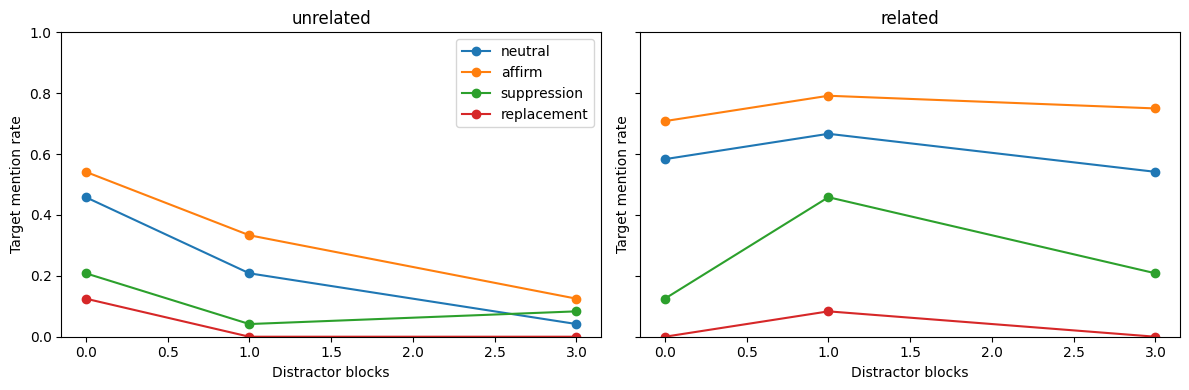

In [3]:
ITEMS=[('banana','apple','Monkeys are pictured holding a curved yellow fruit.'),('elephant','giraffe','The huge gray animal has a trunk and big ears.'),('tiger','lion','A striped orange big cat prowls in the jungle.'),('piano','violin','A classical keyboard instrument has black and white keys.'),('coffee','tea','A dark drink is brewed from roasted beans.'),('ocean','river','A vast body of salt water separates continents.'),('castle','palace','A fortified medieval stone building has towers.'),('bicycle','scooter','A two-wheeled vehicle moves when the pedals turn.')]
UNRELATED='The train arrived at the station. Passengers checked their tickets.'
CONDITIONS=['neutral','affirm','suppression','replacement']
def instruction(x,y,c):
 return {'neutral':f'The topic word is {x}.','affirm':f'Think of {x}.','suppression':f'Do not think of {x}. Do not write the word {x}.','replacement':f'Think of {y} instead of {x}. Do not write the word {x}.'}[c]
def mann_prompt(x,y,cue,cond,kind,level):
 return instruction(x,y,cond)+'\n'+((cue if kind=='related' else UNRELATED)+'\n')*level+'Write one short sentence about whatever comes to mind.'
rows=[]
for k,(x,y,cue) in enumerate(tqdm(ITEMS,desc='Mann pilot')):
 for cond in CONDITIONS:
  for kind in ['unrelated','related']:
   for level in LEVELS:
    p=mann_prompt(x,y,cue,cond,kind,level)
    for j in range(N_SAMPLES):
     output=generation(p,SEED+100000*k+10000*CONDITIONS.index(cond)+1000*(kind=='related')+100*level+j)
     rows.append(dict(concept=x,condition=cond,cue=kind,level=level,sample=j,output=output,mentioned=int(mentions(output,x)),prompt=p))
mann=pd.DataFrame(rows);mann.to_csv(f'{OUT}/mann_generations.csv',index=False)
rates=mann.groupby(['condition','cue','level']).mentioned.agg(['mean','sum','count']).reset_index()
display(rates)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,kind in zip(axes,['unrelated','related']):
 for cond in CONDITIONS:
  d=rates.query('cue==@kind and condition==@cond')
  ax.plot(d.level,d['mean'],marker='o',label=cond)
 ax.set(title=kind,xlabel='Distractor blocks',ylabel='Target mention rate',ylim=(0,1))
axes[0].legend();saveplot('mann_rates.png')

## B: Association cue × suppression/replacement

**Main paired contrast:** within the same concept and the same question, log P(target | suppression) minus log P(target | neutral); also replacement minus suppression. Related-minus-unrelated alone is **not** evidence of rebound. Target probability measures string generation, not internal conceptual activation. Cue questions are exploratory and not fully calibrated.

Cue test:   0%|          | 0/8 [00:00<?, ?it/s]

condition suppression_minus_neutral                  \
                               mean       std count   
cue                                                   
related                   -2.531501  1.426767     8   
unrelated                 -6.162062  1.710171     8   

condition replacement_minus_suppression                  
                                   mean       std count  
cue                                                      
related                       -0.614239  2.542134     8  
unrelated                      0.338407  1.658787     8

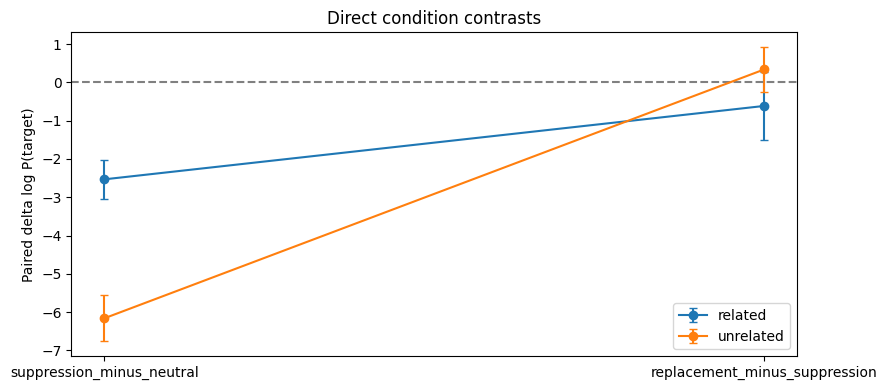

In [4]:
QUESTIONS={'banana':('Which yellow fruit is associated with cartoon monkeys?','Which instrument has black and white keys?'),'elephant':('Which huge animal has a trunk?','Which drink comes from roasted beans?'),'tiger':('Which orange striped big cat lives in Asia?','What two-wheeled vehicle has pedals?'),'piano':('Which keyboard instrument is played in classical music?','Which animal has a trunk?'),'coffee':('Which drink is brewed from roasted beans?','Which medieval building has towers?'),'ocean':('Which vast saltwater body separates continents?','Which instrument has pedals?'),'castle':('Which medieval fortress has towers?','Which curved fruit is yellow?'),'bicycle':('Which two-wheeled vehicle has pedals?','Which vast body of saltwater separates continents?')}
cr=[]
for x,y,_ in tqdm(ITEMS,desc='Cue test'):
 for c in CONDITIONS:
  for kind,q in zip(['related','unrelated'],QUESTIONS[x]):
   p=instruction(x,y,c)+'\n'+q+'\nAnswer with a single word.'
   cr.append(dict(concept=x,condition=c,cue=kind,logprob=score_completion(p,x),prompt=p))
cues=pd.DataFrame(cr);cues.to_csv(f'{OUT}/cue_logprob.csv',index=False)
w=cues.pivot(index=['concept','cue'],columns='condition',values='logprob').reset_index()
w['suppression_minus_neutral']=w.suppression-w.neutral
w['replacement_minus_suppression']=w.replacement-w.suppression
summ=w.groupby('cue')[['suppression_minus_neutral','replacement_minus_suppression']].agg(['mean','std','count'])
display(summ)
fig,ax=plt.subplots(figsize=(9,4))
for kind in ['related','unrelated']:
 d=w.query('cue==@kind')
 cols=['suppression_minus_neutral','replacement_minus_suppression']
 ax.errorbar(cols,d[cols].mean().values,yerr=d[cols].sem().values,marker='o',capsize=3,label=kind)
ax.axhline(0,ls='--',c='gray');ax.set(ylabel='Paired delta log P(target)',title='Direct condition contrasts');ax.legend();saveplot('cue_direct.png')

## C: Zhou-inspired positive/negative minimal pairs

Positive specifies the correct option; Negative excludes both incorrect options. Rotate each option order and gold position to reduce superficial letter bias. This **does not** reproduce Zhou's original 648-item dataset, model or causal intervention, and positive/negative logical complexity differs. A difference in accuracy is behavioral evidence only.

Negation behavior:   0%|          | 0/6 [00:00<?, ?it/s]

correct                    p_gold                
              mean       std count      mean       std count
polarity                                                    
negative  0.296296  0.460911    54  0.302931  0.250333    54
positive  0.666667  0.475831    54  0.547682  0.353354    54

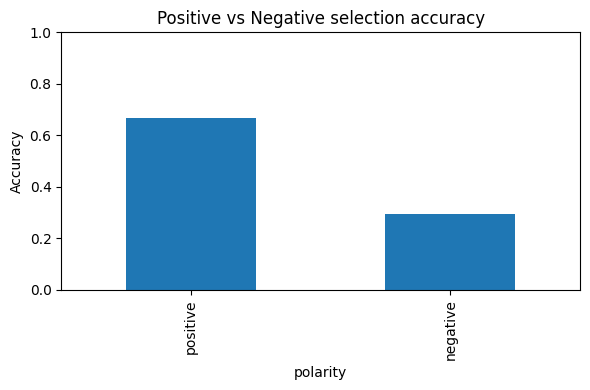

In [5]:
SETS=[['gas','liquid','solid'],['red','blue','green'],['metal','wood','plastic'],['banana','apple','orange'],['cat','dog','bird'],['summer','winter','spring']]
LABELS=['A','B','C']
def zprompt(opts,gold,polarity):
 others=[o for j,o in enumerate(opts) if j!=gold]
 statement=(f'The correct option is {opts[gold]}.' if polarity=='positive' else f'The correct option is not {others[0]} and not {others[1]}. Exactly one option is correct.')
 return 'Choose based on the statement.\n'+statement+'\n'+'\n'.join(f'{l}) {v}' for l,v in zip(LABELS,opts))+'\nReply with ONLY one letter: A, B or C.'
@torch.inference_mode()
def label_prob(prompt):
 pref=chat(prompt);prefix=tok(pref,add_special_tokens=False).input_ids
 ids=[]
 for label in LABELS:
  full=tok(pref+label,add_special_tokens=False).input_ids
  assert full[:len(prefix)]==prefix and len(full)==len(prefix)+1,'non-single-token label; change prompt/labels'
  ids.append(full[-1])
 x=torch.tensor([prefix],device=DEVICE)
 logits=model(x).logits[0,-1,ids].float()
 return logits.softmax(-1).cpu().numpy(),ids
zr=[]
for k,words in enumerate(tqdm(SETS,desc='Negation behavior')):
 for shift in range(3):
  opts=words[shift:]+words[:shift]
  for gold in range(3):
   for polarity in ['positive','negative']:
    prompt=zprompt(opts,gold,polarity);scores,_=label_prob(prompt);pred=int(scores.argmax())
    zr.append(dict(case=k,rotation=shift,gold=gold,polarity=polarity,pred=pred,correct=int(pred==gold),p_gold=float(scores[gold]),p_A=float(scores[0]),p_B=float(scores[1]),p_C=float(scores[2]),prompt=prompt))
zhou=pd.DataFrame(zr);zhou.to_csv(f'{OUT}/zhou_behavior.csv',index=False)
display(zhou.groupby('polarity')[['correct','p_gold']].agg(['mean','std','count']))
fig,ax=plt.subplots(figsize=(6,4));zhou.groupby('polarity').correct.mean().reindex(['positive','negative']).plot.bar(ax=ax)
ax.set(title='Positive vs Negative selection accuracy',ylabel='Accuracy',ylim=(0,1));saveplot('zhou_accuracy.png')

## D: Exploratory layer-wise logit lens

Decode each layer's **answer-label support**, not the activation strength of the underlying semantic concepts themselves. Apply final norm and LM head consistently and verify last-layer scores match the normal model prediction. To test suppression / constructive **mechanisms**, use Zhou's actual data and causal interventions.

In [6]:
@torch.inference_mode()
def lens(prompt):
 probs,ids=label_prob(prompt)
 enc=tok(chat(prompt),return_tensors='pt',add_special_tokens=False).to(DEVICE)
 hs=model(**enc,output_hidden_states=True,return_dict=True).hidden_states
 sequence=np.stack([model.lm_head(model.model.norm(h[:,-1,:]))[0,ids].float().softmax(-1).cpu().numpy() for h in hs])
 assert np.allclose(sequence[-1],probs,atol=.005),(sequence[-1],probs)
 return sequence
opts=SETS[0];p=lens(zprompt(opts,0,'positive'));m=lens(zprompt(opts,0,'negative'))
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,v,title in zip(axes,[p,m],['Positive','Negative']):
 for j,lab in enumerate(LABELS):ax.plot(range(len(v)),v[:,j],label=f'{lab}: {opts[j]}')
 ax.set(title=title,xlabel='Layer index (0=embedding)',ylim=(0,1));ax.legend()
axes[0].set_ylabel('Option-label support');saveplot('zhou_lens.png')
layer_rows=[]
for k,words in enumerate(tqdm(SETS,desc='Layer test')):
 for polarity in ['positive','negative']:
  arr=lens(zprompt(words,0,polarity))
  for layer,values in enumerate(arr):layer_rows.append(dict(case=k,polarity=polarity,layer=layer,p_A=float(values[0]),p_B=float(values[1]),p_C=float(values[2])))
layers=pd.DataFrame(layer_rows);layers.to_csv(f'{OUT}/zhou_lens.csv',index=False)

AssertionError: (array([0.78045845, 0.01594677, 0.20359476], dtype=float32), array([0.76901114, 0.00719388, 0.22379498], dtype=float32))

## Interpretation and limitations

- **Expected Mann-related tendency:** forbidden concepts can rebound under some contexts. An increase in target mention **relative to a matched control** is relevant; cue effects alone cannot prove ironic negation.
- **Expected Zhou-related tendency:** negation can yield lower accuracy and altered late-layer support, but small-model results need not replicate the paper. Logit lens cannot establish suppression or construction circuitry.
- The prompts, lexical items, model size, decoding settings, and semantic relatedness are not exact matches to either paper. This notebook tests **plausible phenomena**, not published numerical estimates.
- Results must be preserved irrespective of direction; if hypotheses change, disclose exploratory vs confirmatory analyses. A formal replication should use authors' published prompts/data and causal intervention methods.


In [ ]:
meta={'model':MODEL_ID,'seed':SEED,'N_SAMPLES':N_SAMPLES,'levels':LEVELS,'torch':torch.__version__,'transformers':__import__('transformers').__version__,'design':'simplified pilot, not exact paper replication'}
with open(f'{OUT}/metadata.json','w') as f:json.dump(meta,f,indent=2)
with zipfile.ZipFile('white_bear_zhou_pilot_v2_results.zip','w',zipfile.ZIP_DEFLATED) as archive:
 for root,dirs,files in os.walk(OUT):
  for name in files:archive.write(os.path.join(root,name))
print('Saved white_bear_zhou_pilot_v2_results.zip')
# For Colab: from google.colab import files; files.download('white_bear_zhou_pilot_v2_results.zip')